In [7]:
import os, sys, time, json, shutil, subprocess, warnings
warnings.filterwarnings("ignore")

try:
    import pyspark
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)
if shutil.which("java") is None:
    subprocess.run("apt-get -qq install -y openjdk-17-jdk-headless > /dev/null", shell=True, check=True)

from google.colab import drive
drive.mount("/content/drive")
PERSIST_DIR = "/content/drive/MyDrive/7006SCN_GSOD"
SCRATCH_DIR = "/content/gsod_scratch"
LOCAL_DIR   = "/content/gsod_local"

def sp(path):
    return path

RAW_DIR     = SCRATCH_DIR + "/raw_csv"
ARCHIVE_DIR = PERSIST_DIR + "/archives"
PARQUET_RAW = LOCAL_DIR + "/parquet/gsod_raw"
FEATURES    = LOCAL_DIR + "/parquet/gsod_features"
PRED_DIR    = LOCAL_DIR + "/parquet/predictions"
MODELS_DIR  = LOCAL_DIR + "/models"
OUT_DIR     = PERSIST_DIR + "/outputs"
for d in [PERSIST_DIR, SCRATCH_DIR, LOCAL_DIR, ARCHIVE_DIR, MODELS_DIR, OUT_DIR]:
    os.makedirs(d, exist_ok=True)

def backup_to_drive(local_path):
    dest = local_path.replace(LOCAL_DIR, PERSIST_DIR)
    shutil.rmtree(dest, ignore_errors=True)
    shutil.copytree(local_path, dest)
    print("backed up ->", dest)

def restore_from_drive(local_path):
    if not os.path.exists(local_path):
        shutil.copytree(local_path.replace(LOCAL_DIR, PERSIST_DIR), local_path)
        print("restored <-", local_path)

YEARS       = [2020, 2021, 2022, 2023]
TRAIN_YEARS = [2020, 2021, 2022]
TEST_YEAR   = 2023
SEED        = 42

from pyspark.sql import SparkSession, functions as F, Window
from pyspark import StorageLevel
TOTAL_RAM_GB = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024**3
DRIVER_MEM = f"{max(2, int(TOTAL_RAM_GB * 0.7))}g"

spark = (SparkSession.builder
         .master("local[*]")
         .appName("7006SCN_GSOD_Task5")
         .config("spark.driver.memory", DRIVER_MEM)
         .config("spark.sql.shuffle.partitions", "64")
         .config("spark.sql.adaptive.enabled", "true")
         .config("spark.serializer", "org.apache.spark.serializer.KryoSerializer")
         .config("spark.sql.files.maxPartitionBytes", str(128 * 1024 * 1024))
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

def n_partitions(df):
    return df.rdd.getNumPartitions()

def safe_persist(df, name, level=StorageLevel.MEMORY_AND_DISK):
    out = df.persist(level)
    out.count()
    return out

def save_csv(pdf, name):
    path = f"{OUT_DIR}/{name}"
    pdf.to_csv(path, index=False)
    print("saved ->", path)

print(f"Spark {spark.version} | master={spark.sparkContext.master} | cores={spark.sparkContext.defaultParallelism} "
      f"| driver memory={DRIVER_MEM} | RAM={TOTAL_RAM_GB:.1f} GB")
print("PERSIST_DIR =", PERSIST_DIR)

restore_from_drive(FEATURES)
restore_from_drive(f"{MODELS_DIR}/prep_pipeline")
restore_from_drive(f"{MODELS_DIR}/LogisticRegression")
restore_from_drive(f"{MODELS_DIR}/DecisionTree")
restore_from_drive(f"{MODELS_DIR}/RandomForest")
restore_from_drive(f"{MODELS_DIR}/GBT")
restore_from_drive(f"{PRED_DIR}/LogisticRegression")
restore_from_drive(f"{PRED_DIR}/DecisionTree")
restore_from_drive(f"{PRED_DIR}/RandomForest")
restore_from_drive(f"{PRED_DIR}/GBT")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Spark 4.0.4 | master=local[*] | cores=2 | driver memory=8g | RAM=12.7 GB
PERSIST_DIR = /content/drive/MyDrive/7006SCN_GSOD


In [6]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pyspark.ml import PipelineModel
from pyspark.ml.classification import (LogisticRegressionModel, DecisionTreeClassificationModel,
                                       RandomForestClassificationModel, GBTClassificationModel)
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

MODEL_CLASSES = {"LogisticRegression": LogisticRegressionModel, "DecisionTree": DecisionTreeClassificationModel,
                 "RandomForest": RandomForestClassificationModel, "GBT": GBTClassificationModel}
MODELS = {n: c.load(sp(f"{MODELS_DIR}/{n}")) for n, c in MODEL_CLASSES.items()}
PREDS  = {n: spark.read.parquet(sp(f"{PRED_DIR}/{n}")) for n in MODELS}
prep_model = PipelineModel.load(sp(f"{MODELS_DIR}/prep_pipeline"))
features = spark.read.parquet(sp(FEATURES))
feature_names = json.load(open(f"{OUT_DIR}/feature_names.json"))
summary3 = pd.read_csv(f"{OUT_DIR}/task3_model_summary.csv")
COLORS = {"LogisticRegression": "#1f77b4", "DecisionTree": "#ff7f0e", "RandomForest": "#2ca02c", "GBT": "#d62728"}

pr_eval  = BinaryClassificationEvaluator(rawPredictionCol="prob", metricName="areaUnderPR")
roc_eval = BinaryClassificationEvaluator(rawPredictionCol="prob", metricName="areaUnderROC")

def add_prob(d):
    return d.withColumn("prob", vector_to_array("probability")[1])

In [8]:
def confusion(p, pred_col="prediction"):
    m = p.agg(*[F.sum(F.when((F.col("label") == l) & (F.col(pred_col) == q), 1).otherwise(0)).alias(k)
                for k, l, q in [("tp", 1, 1), ("fp", 0, 1), ("tn", 0, 0), ("fn", 1, 0)]]).first()
    return m.tp, m.fp, m.tn, m.fn

def metrics_from(p):
    tp, fp, tn, fn = confusion(p)
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1)
    return dict(accuracy=(tp + tn) / (tp + tn + fp + fn), precision=prec, recall=rec, specificity=spec,
                f1=2 * prec * rec / max(prec + rec, 1e-12), balanced_accuracy=(rec + spec) / 2,
                auc_roc=roc_eval.evaluate(p), auc_pr=pr_eval.evaluate(p), tp=tp, fp=fp, tn=tn, fn=fn)

metrics = pd.DataFrame([{"model": n, **metrics_from(p)} for n, p in PREDS.items()])
metrics = metrics.merge(summary3[["model", "hyperparameters", "train_time_s"]], on="model", how="left")
prevalence = PREDS["LogisticRegression"].agg(F.avg("label")).first()[0]
print(f"Test year {TEST_YEAR}: prevalence of extreme next-day = {prevalence:.2%} (PR-AUC of a random model)")
cols = ["model", "accuracy", "precision", "recall", "f1", "balanced_accuracy", "auc_roc", "auc_pr", "train_time_s"]
print(metrics[cols].round(4).to_string(index=False))
save_csv(metrics.round(5), "task5_metrics.csv")

Test year 2023: prevalence of extreme next-day = 15.59% (PR-AUC of a random model)
             model  accuracy  precision  recall     f1  balanced_accuracy  auc_roc  auc_pr  train_time_s
LogisticRegression    0.8658     0.5524  0.7330 0.6300             0.8116   0.8772  0.6837          16.3
      DecisionTree    0.8453     0.5024  0.7965 0.6162             0.8254   0.8865  0.7059          11.0
      RandomForest    0.8748     0.5733  0.7699 0.6572             0.8320   0.9122  0.7616         319.5
               GBT    0.8508     0.5136  0.8108 0.6289             0.8345   0.9148  0.7609         154.1
saved -> /content/drive/MyDrive/7006SCN_GSOD/outputs/task5_metrics.csv


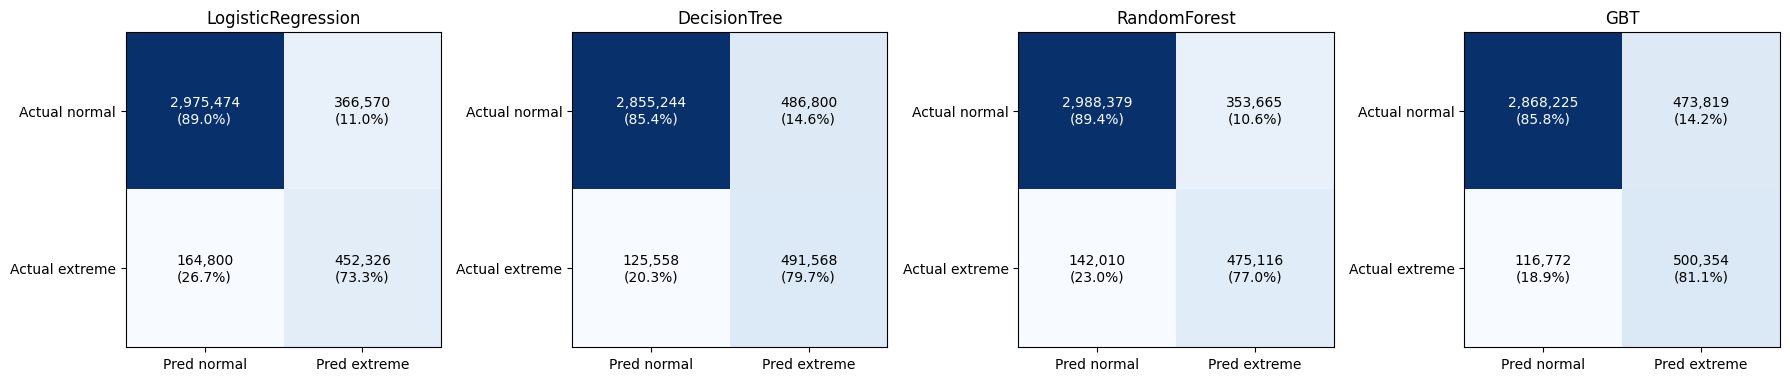

saved -> /content/drive/MyDrive/7006SCN_GSOD/outputs/task5_confusion_long.csv


In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
cm_rows = []
for ax, (_, r) in zip(axes, metrics.iterrows()):
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j]/cm[i].sum():.1%})", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=10)
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Pred normal", "Pred extreme"],
           yticklabels=["Actual normal", "Actual extreme"], title=r.model)
    for (a, pr_), v in {("normal", "normal"): r.tn, ("normal", "extreme"): r.fp,
                        ("extreme", "normal"): r.fn, ("extreme", "extreme"): r.tp}.items():
        cm_rows.append({"model": r.model, "actual": a, "predicted": pr_, "count": int(v)})
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/task5_confusion_matrices.png", dpi=150); plt.show()
save_csv(pd.DataFrame(cm_rows), "task5_confusion_long.csv")

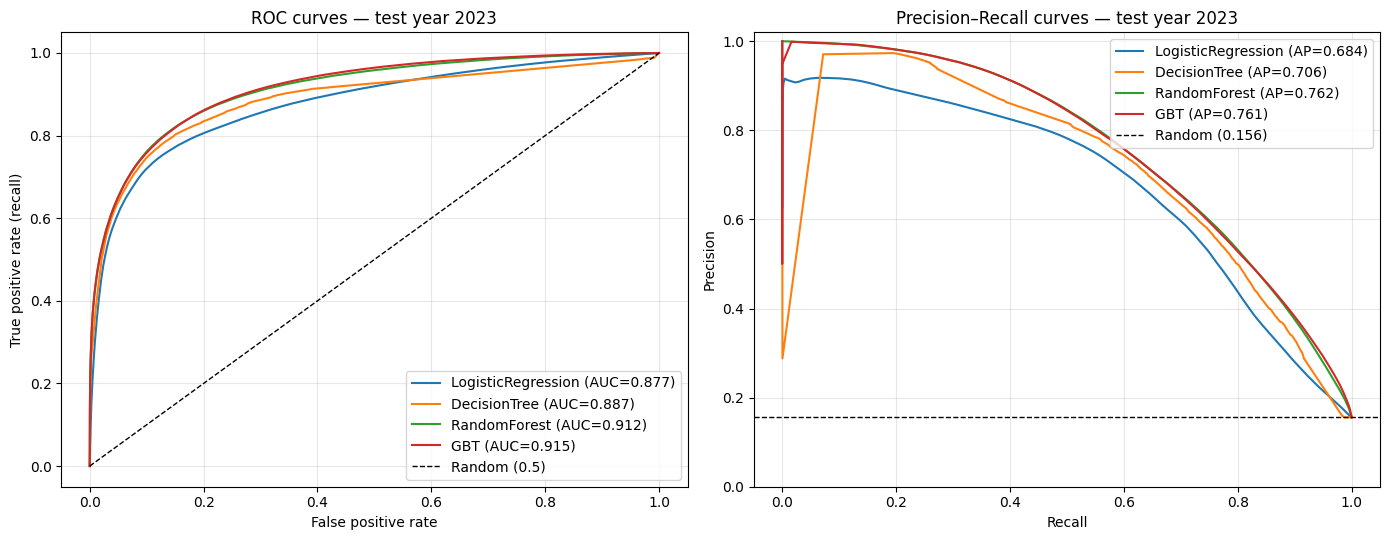

saved -> /content/drive/MyDrive/7006SCN_GSOD/outputs/task5_curve_points.csv


In [10]:
def curve_points(p, bins=1000):
    b = (p.withColumn("bin", F.least(F.floor(F.col("prob") * bins), F.lit(bins - 1)))
          .groupBy("bin").agg(F.sum("label").alias("pos"), F.count("*").alias("n")).toPandas())
    b = b.sort_values("bin", ascending=False)
    b["neg"] = b.n - b.pos
    P, N = b.pos.sum(), b.neg.sum()
    tp, fp = b.pos.cumsum(), b.neg.cumsum()
    out = pd.DataFrame({"threshold": b.bin / bins, "tpr": tp / P, "fpr": fp / N,
                        "precision": tp / (tp + fp), "recall": tp / P})
    return pd.concat([pd.DataFrame([{"threshold": 1.0, "tpr": 0, "fpr": 0, "precision": 1.0, "recall": 0}]), out],
                     ignore_index=True)

CURVES = {n: curve_points(p) for n, p in PREDS.items()}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.5))
for n, c in CURVES.items():
    auc = metrics.set_index("model").loc[n]
    a1.plot(c.fpr, c.tpr, color=COLORS[n], label=f"{n} (AUC={auc.auc_roc:.3f})")
    a2.plot(c.recall, c.precision, color=COLORS[n], label=f"{n} (AP={auc.auc_pr:.3f})")
a1.plot([0, 1], [0, 1], "k--", lw=1, label="Random (0.5)")
a2.axhline(prevalence, color="k", ls="--", lw=1, label=f"Random ({prevalence:.3f})")
a1.set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC curves — test year 2023")
a2.set(xlabel="Recall", ylabel="Precision", title="Precision–Recall curves — test year 2023", ylim=(0, 1.02))
for a in (a1, a2): a.legend(loc="lower right" if a is a1 else "upper right"); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/task5_roc_pr_curves.png", dpi=150); plt.show()

curves_long = pd.concat([c.assign(model=n) for n, c in CURVES.items()], ignore_index=True)
save_csv(curves_long.round(5), "task5_curve_points.csv")

In [11]:
thr = []
for n, c in CURVES.items():
    c = c.copy(); c["f1"] = 2 * c.precision * c.recall / (c.precision + c.recall).replace(0, np.nan)
    best = c.loc[c.f1.idxmax()]
    thr.append({"model": n, "best_threshold": best.threshold, "precision": best.precision,
                "recall": best.recall, "f1": best.f1})
thr = pd.DataFrame(thr)
print(thr.round(4).to_string(index=False))
save_csv(thr.round(5), "task5_thresholds.csv")
BEST_MODEL = metrics.sort_values("auc_pr", ascending=False).iloc[0].model
print("Best model by PR-AUC:", BEST_MODEL)

             model  best_threshold  precision  recall     f1
LogisticRegression           0.722     0.6683  0.6361 0.6518
      DecisionTree           0.768     0.7027  0.6407 0.6703
      RandomForest           0.652     0.6821  0.6752 0.6786
               GBT           0.754     0.6858  0.6716 0.6786
saved -> /content/drive/MyDrive/7006SCN_GSOD/outputs/task5_thresholds.csv
Best model by PR-AUC: RandomForest


In [12]:
STAB_FRACTION = float(os.environ.get("GSOD_STAB_FRACTION", 0.05))
CONT = ["TEMP", "DEWP", "SLP", "VISIB", "WDSP", "MXSPD", "GUST", "MAX", "MIN", "PRCP", "SNDP",
        "TEMP_RANGE", "DEWP_DEPRESSION", "TEMP_CHANGE_1D", "SLP_CHANGE_1D", "TEMP_MEAN_3D", "PRCP_SUM_3D"]
stds = features.filter(F.col("YEAR").isin(TRAIN_YEARS)).agg(*[F.stddev(c).alias(c) for c in CONT]).first().asDict()

stab_base = (features.filter(F.col("YEAR") == TEST_YEAR).sample(fraction=STAB_FRACTION, seed=SEED)
             .withColumn("row_id", F.monotonically_increasing_id()))
stab_base = safe_persist(stab_base, "stab_base")
print(f"stability test rows: {stab_base.count():,}")

def perturb(d, k, seed):
    for i, c in enumerate(CONT):
        d = d.withColumn(c, F.when(F.col(c).isNotNull(), F.col(c) + F.randn(seed + i) * k * stds[c]))
    return d

clean_pred = {n: add_prob(m.transform(prep_model.transform(stab_base))).select("row_id", "label", "prob", "prediction")
              for n, m in MODELS.items()}
clean_pred = {n: safe_persist(p, f"clean_{n}") for n, p in clean_pred.items()}

pert_rows = []
for k in [0.0, 0.01, 0.05, 0.10]:
    noisy = prep_model.transform(perturb(stab_base, k, seed=100)) if k > 0 else prep_model.transform(stab_base)
    for n, m in MODELS.items():
        p = add_prob(m.transform(noisy)).select("row_id", "label", "prob", "prediction")
        j = p.join(clean_pred[n].select("row_id", F.col("prediction").alias("p0"), F.col("prob").alias("prob0")), "row_id")
        flips = j.agg(F.avg((F.col("prediction") != F.col("p0")).cast("double")).alias("flip"),
                      F.avg(F.abs(F.col("prob") - F.col("prob0"))).alias("mean_abs_dprob")).first()
        pert_rows.append({"model": n, "noise_k": k, "pr_auc": pr_eval.evaluate(p), "auc_roc": roc_eval.evaluate(p),
                          "flip_rate": flips.flip, "mean_abs_prob_change": flips.mean_abs_dprob})
    print(f"noise k={k:.2f} done")
pert = pd.DataFrame(pert_rows)
base_pr = pert[pert.noise_k == 0].set_index("model").pr_auc
pert["pr_auc_drop"] = pert.apply(lambda r: base_pr[r.model] - r.pr_auc, axis=1)
print(pert.round(4).to_string(index=False))
save_csv(pert.round(5), "task5_perturbation.csv")

stability test rows: 197,690
noise k=0.00 done
noise k=0.01 done
noise k=0.05 done
noise k=0.10 done
             model  noise_k  pr_auc  auc_roc  flip_rate  mean_abs_prob_change  pr_auc_drop
LogisticRegression     0.00  0.6875   0.8782     0.0000                0.0000       0.0000
      DecisionTree     0.00  0.7112   0.8873     0.0000                0.0000       0.0000
      RandomForest     0.00  0.7655   0.9132     0.0000                0.0000       0.0000
               GBT     0.00  0.7658   0.9158     0.0000                0.0000       0.0000
LogisticRegression     0.01  0.6875   0.8782     0.0004                0.0007       0.0000
      DecisionTree     0.01  0.7086   0.8869     0.0051                0.0037       0.0026
      RandomForest     0.01  0.7653   0.9131     0.0041                0.0036       0.0002
               GBT     0.01  0.7655   0.9156     0.0055                0.0052       0.0003
LogisticRegression     0.05  0.6876   0.8783     0.0020                0.0035   

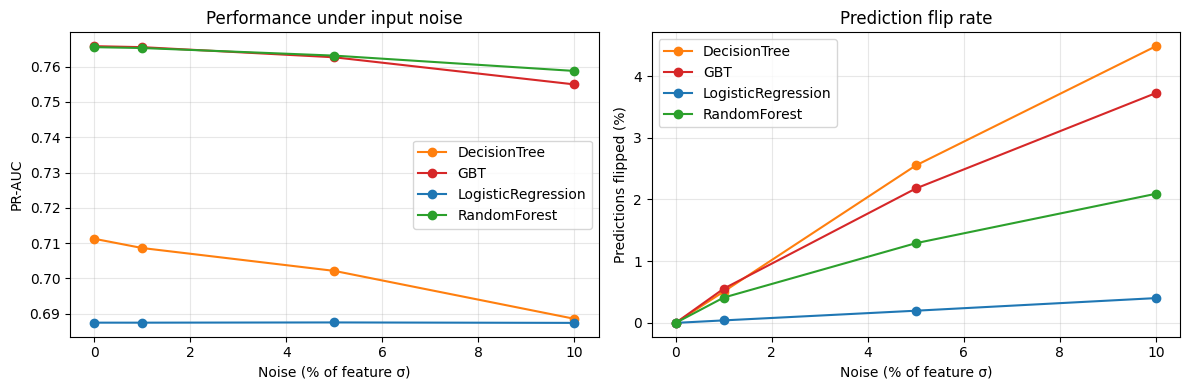

In [13]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for n, g in pert.groupby("model"):
    a1.plot(g.noise_k * 100, g.pr_auc, marker="o", color=COLORS[n], label=n)
    a2.plot(g.noise_k * 100, g.flip_rate * 100, marker="o", color=COLORS[n], label=n)
a1.set(xlabel="Noise (% of feature σ)", ylabel="PR-AUC", title="Performance under input noise")
a2.set(xlabel="Noise (% of feature σ)", ylabel="Predictions flipped (%)", title="Prediction flip rate")
for a in (a1, a2): a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/task5_perturbation.png", dpi=150); plt.show()

In [14]:
from itertools import combinations
STAB_TRAIN_FRACTION = float(os.environ.get("GSOD_STAB_TRAIN_FRACTION", 0.02))
train = features.filter(F.col("YEAR").isin(TRAIN_YEARS))
cnt = {int(r["label"]): r["count"] for r in train.groupBy("label").count().collect()}
tot = sum(cnt.values())
eval_set = safe_persist(prep_model.transform(stab_base).select("row_id", "features", "label"), "eval_set")

boot_rows = []
for n, m in MODELS.items():
    est_cls = {"LogisticRegression": "LogisticRegression", "DecisionTree": "DecisionTreeClassifier",
               "RandomForest": "RandomForestClassifier", "GBT": "GBTClassifier"}[n]
    import pyspark.ml.classification as C
    est = getattr(C, est_cls)()
    pm = {est.getParam(p.name): m.getOrDefault(p) for p in m.params
          if est.hasParam(p.name) and m.isDefined(p) and p.name not in ("weightCol", "seed")}
    est = est.copy(pm)
    est.setWeightCol("w")
    preds, scores = [], []
    for s in [1, 2, 3]:
        sub = (prep_model.transform(train.sample(fraction=STAB_TRAIN_FRACTION, seed=s))
               .withColumn("w", F.when(F.col("label") == 1, tot / (2 * cnt[1])).otherwise(tot / (2 * cnt[0]))))
        mm = est.fit(sub)
        p = add_prob(mm.transform(eval_set)).select("row_id", "label", "prob", F.col("prediction").alias(f"p{s}"))
        scores.append(pr_eval.evaluate(p)); preds.append(p.select("row_id", f"p{s}"))
    joined = preds[0].join(preds[1], "row_id").join(preds[2], "row_id")
    agree = joined.agg(*[F.avg((F.col(f"p{a}") == F.col(f"p{b}")).cast("double")).alias(f"a{a}{b}")
                         for a, b in combinations([1, 2, 3], 2)]).first()
    boot_rows.append({"model": n, "pr_auc_mean": np.mean(scores), "pr_auc_std": np.std(scores, ddof=1),
                      "pr_auc_min": min(scores), "pr_auc_max": max(scores),
                      "mean_pairwise_agreement": np.mean(list(agree.asDict().values()))})
    print(f"{n}: PR-AUC {np.mean(scores):.4f} ± {np.std(scores, ddof=1):.4f}")
boot = pd.DataFrame(boot_rows)
print(boot.round(4).to_string(index=False))
save_csv(boot.round(5), "task5_training_stability.csv")

LogisticRegression: PR-AUC 0.6876 ± 0.0007
DecisionTree: PR-AUC 0.7003 ± 0.0022
RandomForest: PR-AUC 0.7631 ± 0.0002
GBT: PR-AUC 0.7647 ± 0.0011
             model  pr_auc_mean  pr_auc_std  pr_auc_min  pr_auc_max  mean_pairwise_agreement
LogisticRegression       0.6876      0.0007      0.6870      0.6883                   0.9957
      DecisionTree       0.7003      0.0022      0.6982      0.7026                   0.9230
      RandomForest       0.7631      0.0002      0.7628      0.7632                   0.9801
               GBT       0.7647      0.0011      0.7637      0.7659                   0.9574
saved -> /content/drive/MyDrive/7006SCN_GSOD/outputs/task5_training_stability.csv


In [15]:
bp = PREDS[BEST_MODEL]
fair = []
for col in ["CLIMATE_ZONE", "HEMISPHERE"]:
    for g in [r[0] for r in bp.select(col).distinct().collect()]:
        sub = bp.filter(F.col(col) == g)
        tp, fp, tn, fn = confusion(sub)
        n_ = tp + fp + tn + fn
        fair.append({"group_type": col, "group": g, "rows": n_, "prevalence": (tp + fn) / max(n_, 1),
                     "recall": tp / max(tp + fn, 1), "precision": tp / max(tp + fp, 1),
                     "false_alarm_rate": fp / max(fp + tn, 1),
                     "pr_auc": pr_eval.evaluate(sub) if tp + fn > 0 else np.nan})
fair = pd.DataFrame(fair).sort_values(["group_type", "rows"], ascending=[True, False])
print(f"Model: {BEST_MODEL}")
print(fair.round(4).to_string(index=False))
save_csv(fair.round(5), "task5_fairness.csv")

Model: RandomForest
  group_type          group    rows  prevalence  recall  precision  false_alarm_rate  pr_auc
CLIMATE_ZONE      Temperate 1972254      0.0984  0.6013     0.5004            0.0655  0.6048
CLIMATE_ZONE    Subtropical  735164      0.1976  0.8177     0.6409            0.1129  0.8325
CLIMATE_ZONE       Tropical  656736      0.2814  0.8887     0.5473            0.2879  0.7944
CLIMATE_ZONE Polar/Subpolar  595016      0.1562  0.8108     0.6847            0.0691  0.8473
  HEMISPHERE          North 3355497      0.1527  0.7681     0.5773            0.1013  0.7663
  HEMISPHERE          South  603673      0.1735  0.7787     0.5544            0.1314  0.7331
saved -> /content/drive/MyDrive/7006SCN_GSOD/outputs/task5_fairness.csv


SHAP for RandomForest: 826s


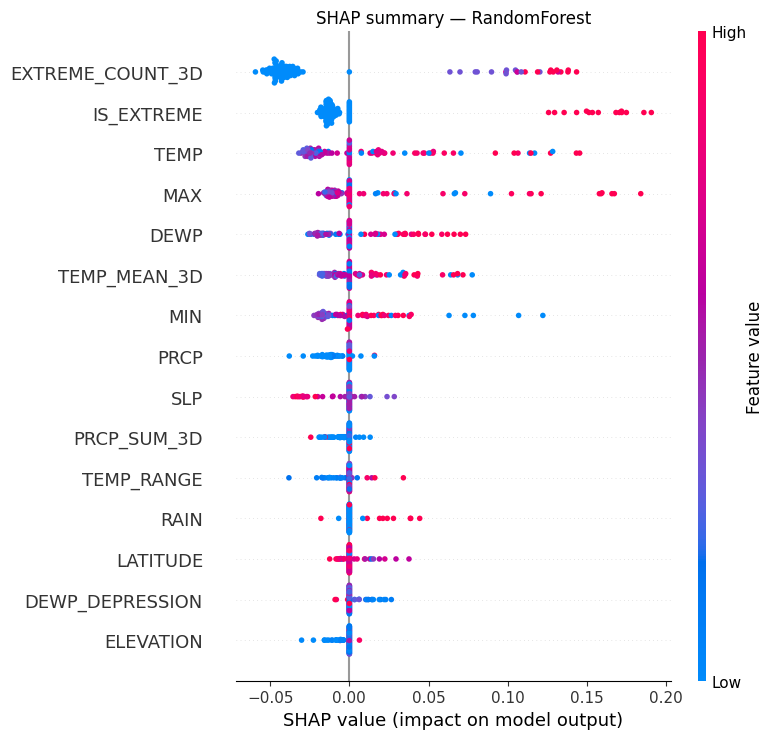

SHAP for LogisticRegression: 44s


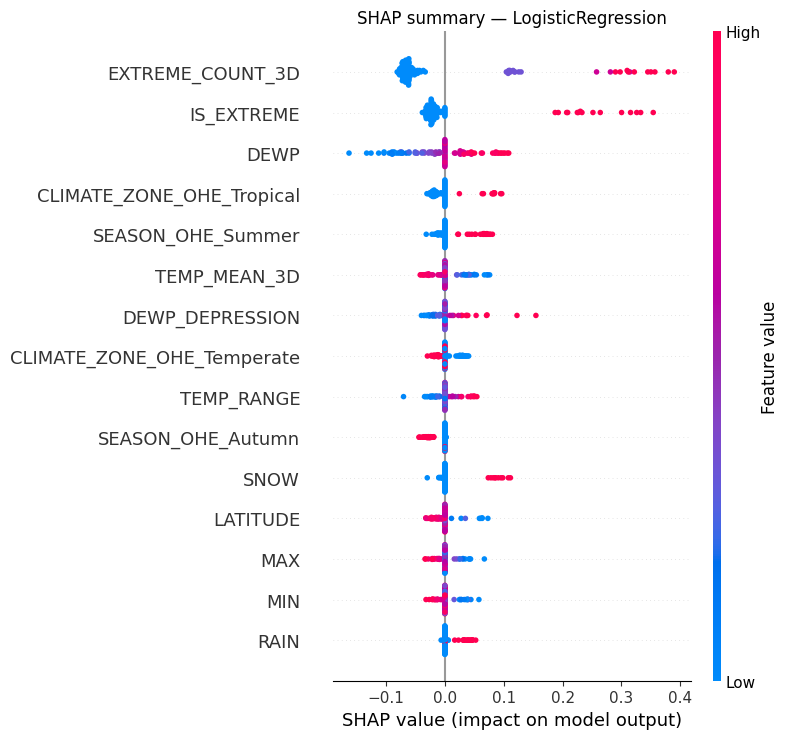

saved -> /content/drive/MyDrive/7006SCN_GSOD/outputs/task5_shap_importance.csv

Top 10 features by mean |SHAP| — RandomForest
       model          feature  mean_abs_shap
RandomForest EXTREME_COUNT_3D       0.058701
RandomForest       IS_EXTREME       0.032792
RandomForest             TEMP       0.030944
RandomForest              MAX       0.024730
RandomForest             DEWP       0.016803
RandomForest     TEMP_MEAN_3D       0.015706
RandomForest              MIN       0.015113
RandomForest             PRCP       0.008006
RandomForest              SLP       0.005845
RandomForest      PRCP_SUM_3D       0.003357

Top 10 features by mean |SHAP| — LogisticRegression
             model                    feature  mean_abs_shap
LogisticRegression           EXTREME_COUNT_3D       0.102684
LogisticRegression                 IS_EXTREME       0.056089
LogisticRegression                       DEWP       0.044752
LogisticRegression  CLIMATE_ZONE_OHE_Tropical       0.019202
LogisticRegression   

In [16]:
try:
    import shap
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=True)
    import shap
from pyspark.ml.linalg import Vectors

N_EXPLAIN = int(os.environ.get("GSOD_SHAP_ROWS", 100))
sample_pd = (eval_set.orderBy(F.rand(SEED)).limit(2000)
             .select(vector_to_array("features").alias("x"), "label").toPandas())
X = np.vstack(sample_pd.x.values)
background = shap.kmeans(X, 10)
X_explain = X[:N_EXPLAIN]

def make_predict(model):
    def f(arr):
        sdf = spark.createDataFrame([(Vectors.dense(r),) for r in np.asarray(arr)], ["features"])
        return np.array([r[0] for r in add_prob(model.transform(sdf)).select("prob").collect()])
    return f

SHAP_MODELS = [BEST_MODEL] + (["LogisticRegression"] if BEST_MODEL != "LogisticRegression" else ["RandomForest"])
shap_tables = []
for n in SHAP_MODELS:
    t0 = time.perf_counter()
    explainer = shap.KernelExplainer(make_predict(MODELS[n]), background)
    sv = np.array(explainer.shap_values(X_explain, nsamples=200, silent=True))
    print(f"SHAP for {n}: {time.perf_counter()-t0:,.0f}s")
    imp = pd.DataFrame({"model": n, "feature": feature_names, "mean_abs_shap": np.abs(sv).mean(0)})
    shap_tables.append(imp)
    plt.figure()
    shap.summary_plot(sv, X_explain, feature_names=feature_names, max_display=15, show=False)
    plt.title(f"SHAP summary — {n}"); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/task5_shap_{n}.png", dpi=150, bbox_inches="tight"); plt.show()
shap_imp = pd.concat(shap_tables, ignore_index=True)
save_csv(shap_imp.round(6), "task5_shap_importance.csv")
for n in SHAP_MODELS:
    print(f"\nTop 10 features by mean |SHAP| — {n}")
    print(shap_imp[shap_imp.model == n].sort_values("mean_abs_shap", ascending=False).head(10).to_string(index=False))